# Customer Segmentation Using K-Means Clustering

## Objective
To group mall customers into meaningful segments using the K-Means clustering algorithm based on their age, annual income, and spending score.

## Problem Statement
Understanding customer behavior helps businesses develop targeted marketing strategies. This project uses unsupervised machine learning to identify customer groups with similar characteristics and spending patterns.

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Jupyter Notebook

## Expected Outcome
Identify customer segments, visualize the clusters, and interpret their spending behavior to support better marketing decisions.

In [1]:
import os

# Limit OpenMP threads to avoid the K-Means Windows/MKL warning
os.environ["OMP_NUM_THREADS"] = "1"

print("Thread configuration set successfully.")

Thread configuration set successfully.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the dataset
df = pd.read_csv("Mall_Customers.csv")

# Display dataset information
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

Dataset shape: (200, 5)

First five rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB

Missing values in each column:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


## Exploratory Data Analysis

Exploratory Data Analysis (EDA) helps us understand the dataset's structure, feature distributions, and relationships between customer attributes. It also helps identify patterns that may be useful for customer segmentation.

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


Gender distribution:
Gender
Female    112
Male       88
Name: count, dtype: int64


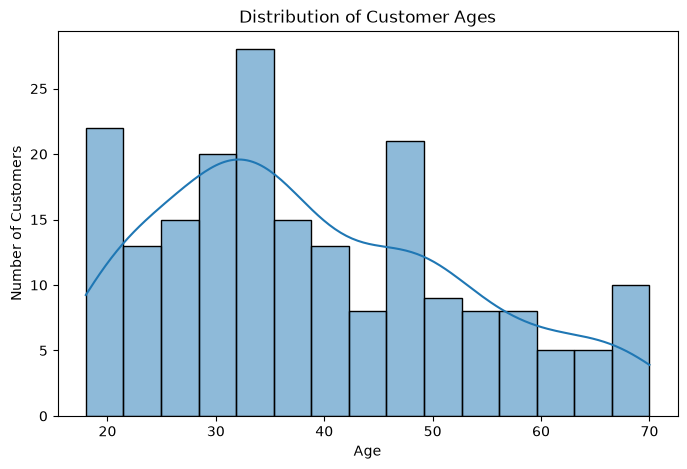

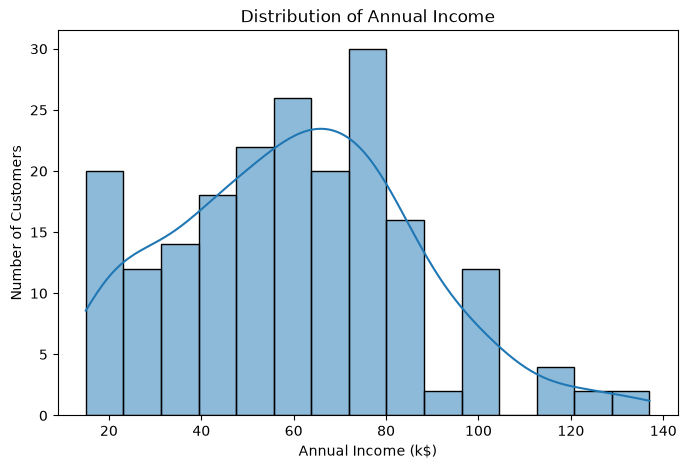

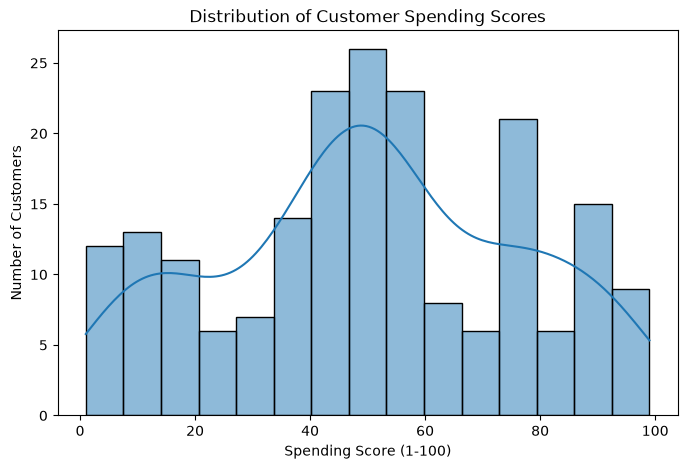

In [4]:
# Statistical summary of numerical columns
display(df.describe())

# Distribution of customer genders
print("Gender distribution:")
print(df["Gender"].value_counts())

# Distribution of customer ages
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], bins=15, kde=True)
plt.title("Distribution of Customer Ages")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

# Distribution of annual income
plt.figure(figsize=(8, 5))
sns.histplot(df["Annual Income (k$)"], bins=15, kde=True)
plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Number of Customers")
plt.show()

# Distribution of spending scores
plt.figure(figsize=(8, 5))
sns.histplot(df["Spending Score (1-100)"], bins=15, kde=True)
plt.title("Distribution of Customer Spending Scores")
plt.xlabel("Spending Score (1-100)")
plt.ylabel("Number of Customers")
plt.show()

## Data Preprocessing

Data preprocessing prepares the dataset for machine learning. In this project, we will select relevant customer features, check for duplicate records, and standardize numerical values before applying K-Means clustering.

The `CustomerID` column will not be used because it is only an identifier. We will initially use `Age`, `Annual Income (k$)`, and `Spending Score (1-100)` as clustering features.

In [5]:
# Check for duplicate records
print("Number of duplicate rows:", df.duplicated().sum())

# Select features for clustering
features = [
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
]

X = df[features].copy()

# Check for missing values in selected features
print("\nMissing values in selected features:")
print(X.isnull().sum())

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nOriginal feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)

# Display a few scaled values
print("\nFirst five scaled rows:")
print(X_scaled[:5])

Number of duplicate rows: 0

Missing values in selected features:
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Original feature shape: (200, 3)
Scaled feature shape: (200, 3)

First five scaled rows:
[[-1.42456879 -1.73899919 -0.43480148]
 [-1.28103541 -1.73899919  1.19570407]
 [-1.3528021  -1.70082976 -1.71591298]
 [-1.13750203 -1.70082976  1.04041783]
 [-0.56336851 -1.66266033 -0.39597992]]


## Finding the Optimal Number of Clusters

The Elbow Method helps determine a suitable number of clusters for K-Means. We train the algorithm with different values of K and record the inertia for each value.

Inertia measures the sum of squared distances between data points and their assigned cluster centers. We look for an elbow in the curve, where increasing K further produces smaller improvements.

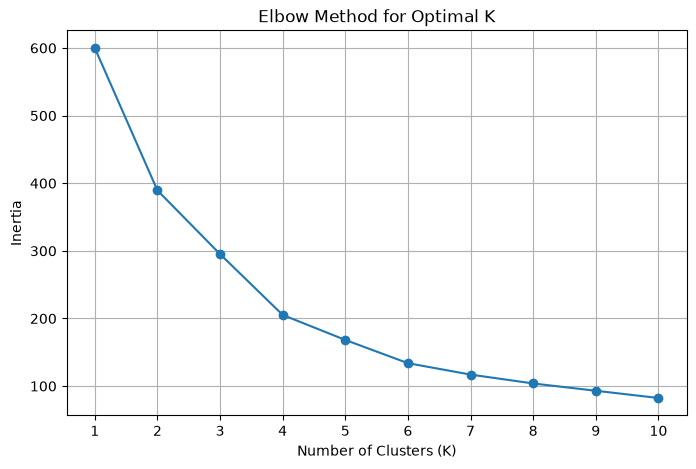

In [6]:
# Calculate inertia for different values of K
inertia_values = []

k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot the Elbow Method graph
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

## Evaluating the Number of Clusters Using Silhouette Score

The Silhouette Score measures how well each data point fits within its assigned cluster compared with other clusters.

The score ranges from -1 to 1:
- Near 1: Customers are well separated into clusters.
- Near 0: Clusters overlap.
- Below 0: Some customers may be assigned to inappropriate clusters.

We will compare silhouette scores for K values from 2 to 10 and use the results alongside the Elbow Method to select K.

,Number of Clusters (K),Silhouette Score
0,2,0.335472
1,3,0.357793
2,4,0.403958
3,5,0.416643
4,6,0.428417
5,7,0.417232
6,8,0.408207
7,9,0.417693
8,10,0.406554


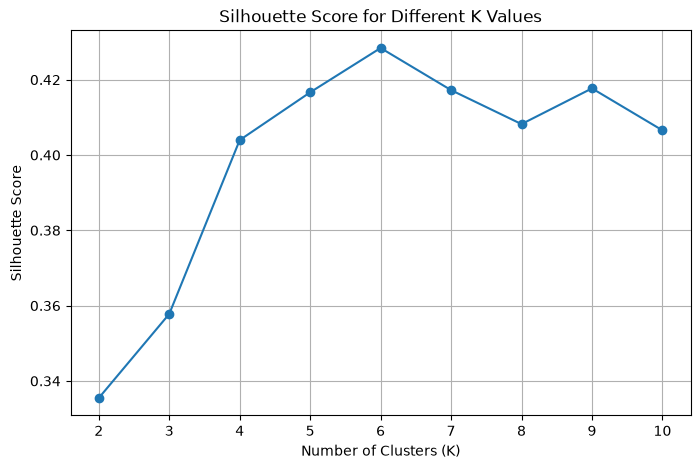

K with the highest silhouette score: 6


In [7]:
# Calculate silhouette scores for different K values
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)

# Display the results
results = pd.DataFrame({
    "Number of Clusters (K)": list(k_values),
    "Silhouette Score": silhouette_scores
})

display(results)

# Plot silhouette scores
plt.figure(figsize=(8, 5))
plt.plot(k_values, silhouette_scores, marker="o")
plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# Identify the K with the highest silhouette score
best_k_silhouette = list(k_values)[np.argmax(silhouette_scores)]

print("K with the highest silhouette score:", best_k_silhouette)

In [8]:
# Set the number of clusters based on silhouette score
k = 6

# Train the K-Means model
kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

# Assign cluster labels to customers
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means model trained successfully!")
print("Number of clusters:", k)

print("\nNumber of customers in each cluster:")
print(df["Cluster"].value_counts().sort_index())

print("\nFirst five customers with cluster labels:")
display(df.head())

K-Means model trained successfully!
Number of clusters: 6

Number of customers in each cluster:
Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64

First five customers with cluster labels:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,4
2,3,Female,20,16,6,5
3,4,Female,23,16,77,4
4,5,Female,31,17,40,5


## Visualizing Customer Segments

Visualization helps us understand the similarities and differences between the customer groups identified by K-Means. We will create scatter plots to compare annual income with spending score and examine how age relates to customer spending behavior.

Each color represents a different cluster assigned by the model.

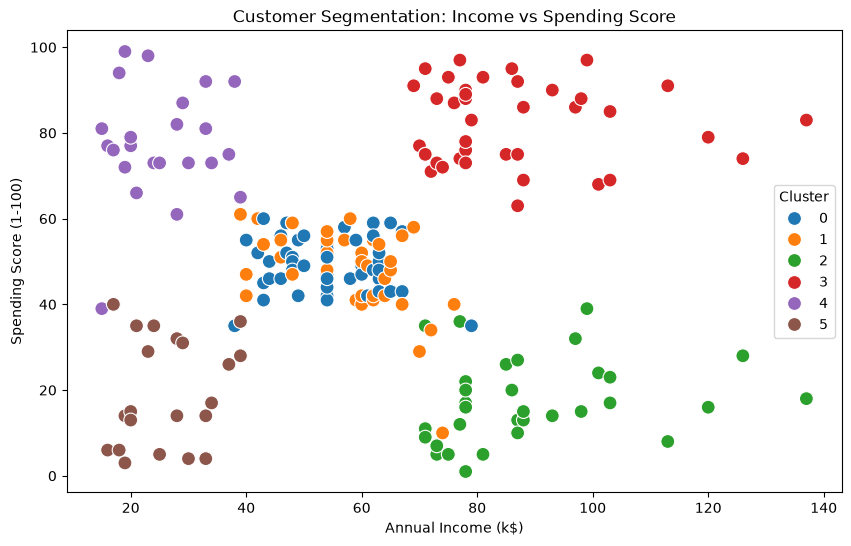

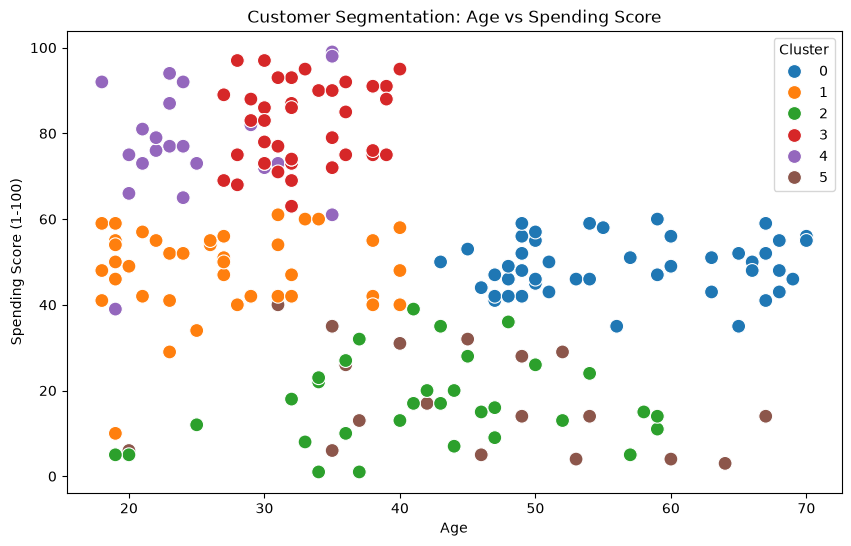

In [9]:
# Visualize Annual Income vs Spending Score
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=100
)

plt.title("Customer Segmentation: Income vs Spending Score")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()


# Visualize Age vs Spending Score
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    s=100
)

plt.title("Customer Segmentation: Age vs Spending Score")
plt.xlabel("Age")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.show()

## Customer Segment Analysis

After clustering, we analyze the average age, annual income, and spending score of each group. These statistics help us understand customer behavior and identify potential marketing opportunities.

The cluster labels are numerical, so we will interpret each cluster using its average feature values rather than assuming that a particular cluster number represents a specific type of customer.

In [10]:
# Calculate average characteristics of each cluster
cluster_summary = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

display(cluster_summary)

,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Cluster,,,,
0,45,56.33,54.27,49.07
1,39,26.79,57.10,48.13
2,33,41.94,88.94,16.97
3,39,32.69,86.54,82.13
4,23,25.00,25.26,77.61
5,21,45.52,26.29,19.38


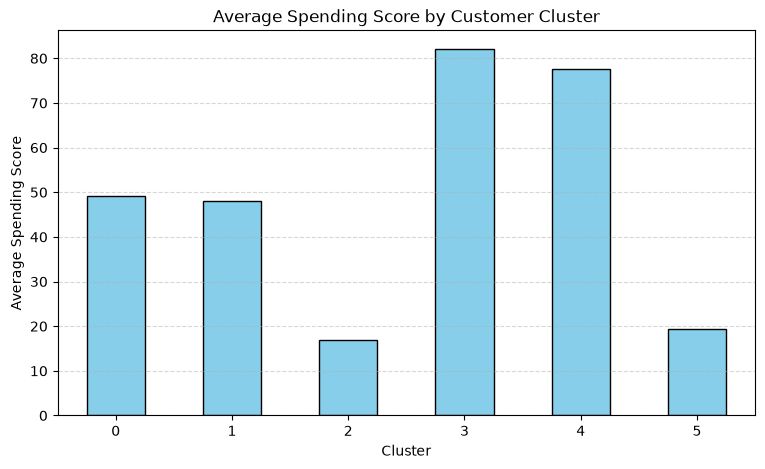

In [11]:
plt.figure(figsize=(9, 5))

cluster_summary["Average_Spending_Score"].plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Average Spending Score by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Average Spending Score")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.show()

## Interpretation of Customer Segments

Based on the average annual income and spending score, the six clusters represent different customer behaviors. Some customers have high incomes but low spending scores, while others have lower incomes and high spending scores.

These insights can help businesses identify potential premium customers, customers who may respond to targeted promotions, and customers who consistently spend less. Segment names are descriptive interpretations of the cluster averages rather than labels learned directly by the K-Means algorithm.

In [12]:
# Assign descriptive names to the clusters
cluster_names = {
    0: "Medium Spenders - Older",
    1: "Medium Spenders - Younger",
    2: "Low Spenders - High Income",
    3: "High Spenders - High Income",
    4: "High Spenders - Low Income",
    5: "Low Spenders - Low Income"
}

df["Segment"] = df["Cluster"].map(cluster_names)

# Display the number of customers in each segment
print("Customer segment distribution:")
print(df["Segment"].value_counts())

# Display sample customer records
display(df[[
    "CustomerID",
    "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)",
    "Cluster",
    "Segment"
]].head(10))

Customer segment distribution:
Segment
Medium Spenders - Older        45
Medium Spenders - Younger      39
High Spenders - High Income    39
Low Spenders - High Income     33
High Spenders - Low Income     23
Low Spenders - Low Income      21
Name: count, dtype: int64


,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Cluster,Segment
0,1,19,15,39,4,High Spenders - Low Income
1,2,21,15,81,4,High Spenders - Low Income
2,3,20,16,6,5,Low Spenders - Low Income
3,4,23,16,77,4,High Spenders - Low Income
4,5,31,17,40,5,Low Spenders - Low Income
5,6,22,17,76,4,High Spenders - Low Income
6,7,35,18,6,5,Low Spenders - Low Income
7,8,23,18,94,4,High Spenders - Low Income
8,9,64,19,3,5,Low Spenders - Low Income
9,10,30,19,72,4,High Spenders - Low Income


## Final Customer Segmentation Visualization

This visualization presents the six customer segments identified by K-Means clustering. Different colors represent different customer groups, while the axes show annual income and spending score.

The visualization helps identify high-value customers, low-spending customers, and customers who may respond to targeted marketing campaigns.

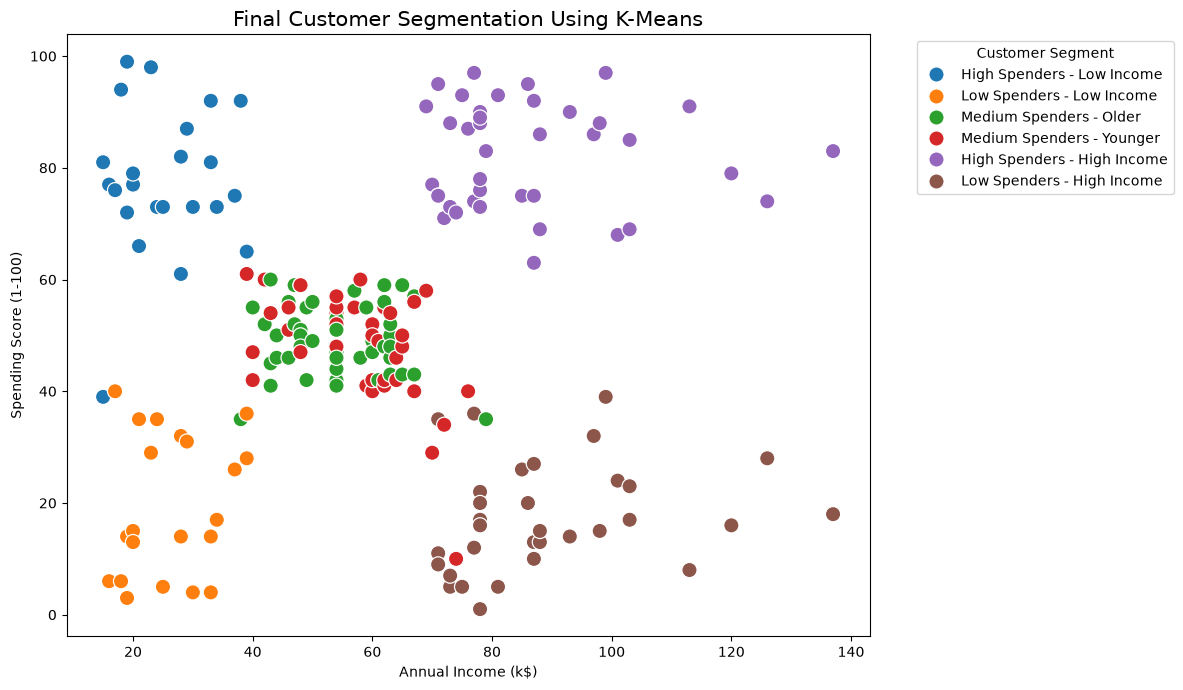

In [13]:
# Visualize the final customer segments
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Segment",
    palette="tab10",
    s=120
)

plt.title("Final Customer Segmentation Using K-Means", fontsize=15)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Customer Segment", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [14]:
# Summarize the final segments
final_summary = df.groupby("Segment").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

display(final_summary)

,Customer_Count,Average_Age,Average_Annual_Income,Average_Spending_Score
Segment,,,,
High Spenders - High Income,39,32.69,86.54,82.13
High Spenders - Low Income,23,25.00,25.26,77.61
Low Spenders - High Income,33,41.94,88.94,16.97
Low Spenders - Low Income,21,45.52,26.29,19.38
Medium Spenders - Older,45,56.33,54.27,49.07
Medium Spenders - Younger,39,26.79,57.10,48.13


## Conclusion

In this project, K-Means clustering was used to segment mall customers based on age, annual income, and spending score. The Elbow Method and Silhouette Score were used to help determine a suitable number of clusters.

The selected model identified six customer groups with different demographic and spending characteristics. Visualizations and cluster summaries helped interpret these groups, including high-income customers with low spending scores and customers with high spending scores across different income levels.

These insights can help businesses understand customer behavior, design targeted marketing campaigns, improve customer engagement, and make better data-driven decisions.

Overall, this project demonstrates how unsupervised machine learning can be applied to customer segmentation using Python and Scikit-learn.